# Spike S02: how pure are CSB "sugarcane" fields? (CDL 2023, Iberia)

**Question.** A CSB field's `CDL2023` value is the *majority* CDL class inside the polygon. How much of a "cane" field is really cane pixel by pixel, and how much CDL cane lies outside any CSB field?

**Decision rule (stated before looking).** The CSB majority labels are adopted as Module A training labels for Iberia if:
1. the median cane-pixel share inside 2023 cane fields is at least 0.90;
2. at least 90 % of 2023 cane fields have a cane share of at least 0.70;
3. at least 80 % of Iberia's CDL cane pixels fall inside CSB fields (so the polygons cover the crop).

If rule 1 or 2 fails, plan a purity filter (keep only fields above a threshold) and record it in DQ-10.

Links: H-24 (CDL labels accurate enough), DQ-10 (label quality and splits), DQ-05 (unit of classification). Source: USDA NASS CDL 2023, 30 m, `2023_30m_cdls.zip`, downloaded 2026-11-06; public domain (NASS metadata).

## 1. Concept: what a raster really is

A raster file is a 2-D array plus a recipe that turns array positions into map coordinates:

```
 array (rows x cols of class codes)        + transform (the recipe)
   col 0  col 1  col 2                        x = x0 + col * 30
 r0  45     45     61                         y = y0 - row * 30
 r1  45     45      5                       (x0, y0) = top-left corner, metres
 r2   1     45      5                       30 = pixel size in metres
```

- `rasterio` opens the file without reading it all. The national CDL is over 150,000 x 100,000 pixels, too big for memory, so we read only a **window** around Iberia.
- The file also stores its **CRS**. The CDL and the CSB both use an Albers Equal Area projection, so they should line up without reprojection. The code checks this instead of assuming it.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.windows import from_bounds
from rasterio import features
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ROOT = Path.cwd().parents[1] if Path.cwd().name == "exploration" else Path.cwd()
FIG = ROOT / "docs/research/spikes/figures"
CDL_TIF = next((ROOT / "data/raw/cdl").rglob("*2023*.tif"))
print("CDL file:", CDL_TIF.relative_to(ROOT))

la = gpd.read_parquet(ROOT / "data/interim/csb/csb1825_louisiana.parquet")
codes = pd.read_csv(ROOT / "data/reference/cdl_codes.csv").set_index("code")["name"]
PARISH = "Iberia"
p = la[la["CNTY"] == PARISH].copy()

with rasterio.open(CDL_TIF) as src:
    print("raster size:", src.width, "x", src.height, "| pixel:", src.res, "m | dtype:", src.dtypes[0])
    print("CDL CRS :", src.crs.to_wkt()[:60], "...")
    print("CSB CRS :", p.crs.to_wkt()[:60], "...")
    same = src.crs == p.crs or src.crs.to_wkt() == p.crs.to_wkt()
    print("same CRS object:", same)
    if not same:
        p = p.to_crs(src.crs)   # bring the vectors onto the raster's grid, never the other way round
        print("-> CSB reprojected to the CDL CRS")
    crs = src.crs

CDL file: data/raw/cdl/2023_30m_cdls.tif


raster size: 153811 x 96523 | pixel: (30.0, 30.0) m | dtype: uint8
CDL CRS : PROJCS["NAD83 / Conus Albers",GEOGCS["NAD83",DATUM["North_Am ...
CSB CRS : PROJCRS["Albers_Conic_Equal_Area",BASEGEOGCRS["NAD83",DATUM[ ...
same CRS object: True


## 2. Read only the Iberia window

`from_bounds` converts the parish's bounding box (in metres) into a row/column window. We pad it by 300 m (10 pixels) so fields on the edge aren't cut.

In [2]:
pad = 300
xmin, ymin, xmax, ymax = p.total_bounds
with rasterio.open(CDL_TIF) as src:
    win = from_bounds(xmin - pad, ymin - pad, xmax + pad, ymax + pad, src.transform).round_offsets().round_lengths()
    cdl = src.read(1, window=win)              # the class-code array for Iberia only
    transform = src.window_transform(win)      # recipe for this sub-array
print("window array:", cdl.shape, "pixels =", f"{cdl.size:,}", "| memory:", f"{cdl.nbytes / 1e6:.1f} MB")
vals, counts = np.unique(cdl, return_counts=True)
top = pd.Series(counts, index=vals).sort_values(ascending=False).head(10)
pd.DataFrame({"pixels": top, "class": top.index.map(codes)})

window array: (1218, 1619) pixels = 1,971,942 | memory: 2.0 MB


,pixels,class
190,551941,Woody Wetlands
45,459581,Sugarcane
195,237763,Herbaceous Wetlands
176,142761,Grassland/Pasture
111,140736,Open Water
122,107892,Developed/Low Intensity
61,100259,Fallow/Idle Cropland
121,54916,Developed/Open Space
0,45786,Background
123,38522,Developed/Med Intensity


## 3. Map: CDL sugarcane pixels with CSB outlines on top

Green = CDL sugarcane pixels, grey = any other class, white = background. Black lines = CSB field boundaries. If the two datasets line up, the green should sit inside the outlines.

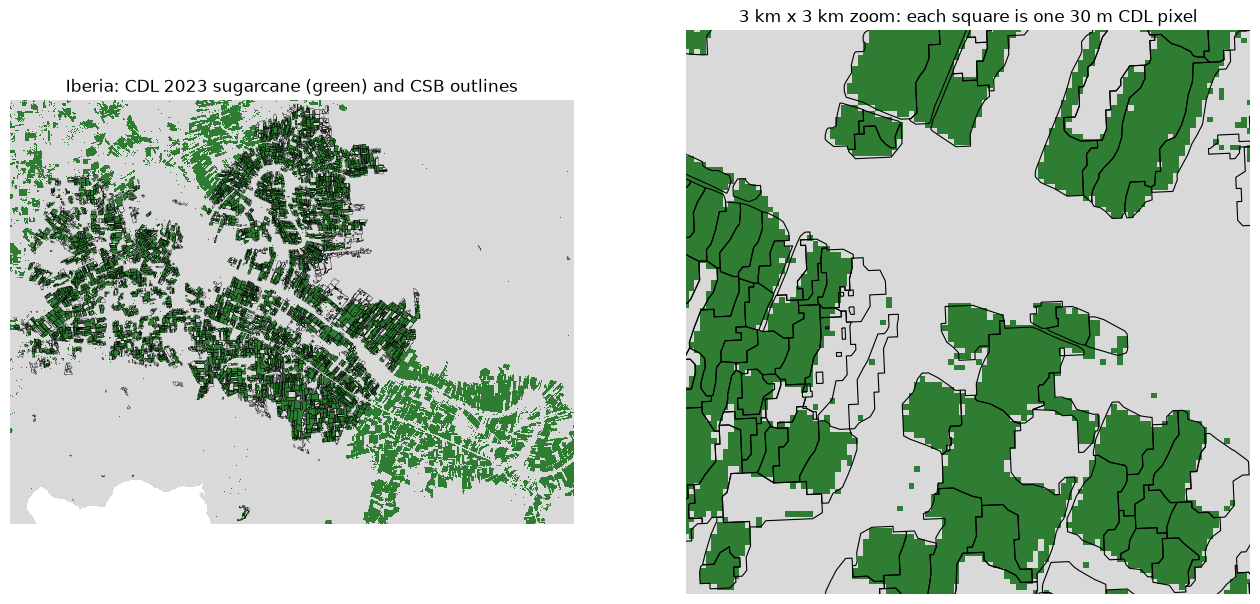

In [3]:
view = np.where(cdl == 45, 2, np.where(cdl == 0, 0, 1))
ext = rasterio.plot.plotting_extent(cdl, transform) if hasattr(rasterio, "plot") else None
import rasterio.plot
ext = rasterio.plot.plotting_extent(cdl, transform)

cx, cy = p.loc[p.CDL2023 == 45, "INSIDE_X"].median(), p.loc[p.CDL2023 == 45, "INSIDE_Y"].median()
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, half in zip(axes, [None, 1500]):
    ax.imshow(view, extent=ext, cmap=ListedColormap(["white", "#d9d9d9", "#2e7d32"]), interpolation="nearest")
    p.boundary.plot(ax=ax, color="black", linewidth=0.25 if half is None else 0.8)
    if half:
        ax.set_xlim(cx - half, cx + half); ax.set_ylim(cy - half, cy + half)
    ax.set_axis_off()
axes[0].set_title(f"{PARISH}: CDL 2023 sugarcane (green) and CSB outlines")
axes[1].set_title("3 km x 3 km zoom: each square is one 30 m CDL pixel")
fig.savefig(FIG / "S02_cdl_vs_csb.png", dpi=130, bbox_inches="tight")
plt.show()

## 4. Concept: zonal statistics (pixels to fields)

"Zonal statistics" means summarising the pixels that fall inside each zone (here, each field). The trick we use:

```
 1. rasterize: burn each field's row number into a new array on the SAME grid as the CDL
      field_id array        cdl array
      7 7 7 0               45 45 61  1
      7 7 8 8      +        45 45  5  5      ->  pairs (field, class) per pixel
      0 8 8 8                1  5  5  5
 2. count pixels per (field, class) pair with one numpy pass
 3. share of class k in field f = count(f, k) / count(f, all)
```

`rasterio.features.rasterize` assigns a pixel to a polygon when the **pixel centre** falls inside it (the default rule). Pixels on a boundary therefore go to one field or the other, never both.

In [4]:
p = p.reset_index(drop=True)
p["fid"] = np.arange(1, len(p) + 1)            # 0 is reserved for 'no field'
fid = features.rasterize(zip(p.geometry, p.fid), out_shape=cdl.shape, transform=transform, fill=0, dtype="int32")

def class_shares(fid_arr, cdl_arr):
    """Return a DataFrame: rows = field id, columns = CDL class, values = pixel counts."""
    m = fid_arr > 0
    pair = fid_arr[m].astype(np.int64) * 256 + cdl_arr[m]   # CDL codes are < 256: one integer per pair
    u, n = np.unique(pair, return_counts=True)
    t = pd.DataFrame({"fid": u // 256, "cls": u % 256, "n": n})
    return t.pivot_table(index="fid", columns="cls", values="n", fill_value=0)

tab = class_shares(fid, cdl)
p = p.set_index("fid")
p["n_px"] = tab.sum(axis=1)
p["cane_share"] = (tab.get(45, 0) / p["n_px"])
p["majority_px"] = tab.idxmax(axis=1)
print("fields with at least one pixel:", int(p.n_px.notna().sum()), "of", len(p))
p[["CSBACRES", "CDL2023", "n_px", "cane_share", "majority_px"]].head()

fields with at least one pixel: 5632 of 5632


,CSBACRES,CDL2023,n_px,cane_share,majority_px
fid,,,,,
1,3.536242,45,16.0,0.562500,45
2,8.222784,92,37.0,0.000000,92
3,6.795606,45,31.0,0.806452,45
4,7.285633,92,31.0,0.000000,92
5,8.095249,45,36.0,1.000000,45


## 5. Purity of cane fields

For each field labelled cane in 2023, the share of its pixels that the CDL calls cane. A share of 1.0 means a pure cane field.

2023 cane fields: 4,213
median cane share 0.949 | 25th pct 0.889 | 10th pct 0.792
share of cane fields with cane_share >= 0.70: 94.9%
share with cane_share >= 0.90: 71.5%

CSB CDL2023 label equals our own pixel-majority class: 99.5% of all Iberia fields


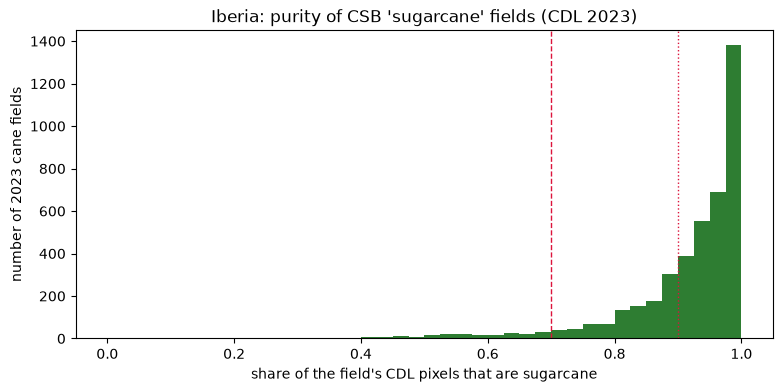

In [5]:
cane = p[p.CDL2023 == 45].dropna(subset=["cane_share"])
q = cane.cane_share.quantile([0.1, 0.25, 0.5])
print(f"2023 cane fields: {len(cane):,}")
print(f"median cane share {q[0.5]:.3f} | 25th pct {q[0.25]:.3f} | 10th pct {q[0.1]:.3f}")
print(f"share of cane fields with cane_share >= 0.70: {(cane.cane_share >= 0.70).mean():.1%}")
print(f"share with cane_share >= 0.90: {(cane.cane_share >= 0.90).mean():.1%}")
agree = (p.CDL2023 == p.majority_px).mean()
print(f"\nCSB CDL2023 label equals our own pixel-majority class: {agree:.1%} of all Iberia fields")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(cane.cane_share, bins=np.linspace(0, 1, 41), color="#2e7d32")
ax.axvline(0.7, color="crimson", ls="--", lw=1); ax.axvline(0.9, color="crimson", ls=":", lw=1)
ax.set_xlabel("share of the field's CDL pixels that are sugarcane"); ax.set_ylabel("number of 2023 cane fields")
ax.set_title(f"{PARISH}: purity of CSB 'sugarcane' fields (CDL 2023)")
fig.savefig(FIG / "S02_cane_purity.png", dpi=130, bbox_inches="tight")
plt.show()

## 6. Is impurity an edge effect?

If impure pixels sit mainly on field edges (30 m pixels straddling the boundary or a headland road), shrinking each field inward by one pixel (-30 m buffer) should raise the purity. If purity stays low, the problem is inside the field (a mislabelled field, or a real mix).

In [6]:
inner = p.copy()
inner["geometry"] = inner.geometry.buffer(-30)
inner = inner[~inner.geometry.is_empty]
fid_in = features.rasterize(zip(inner.geometry, inner.index), out_shape=cdl.shape, transform=transform, fill=0, dtype="int32")
tab_in = class_shares(fid_in, cdl)
inner["cane_share_in"] = tab_in.get(45, 0) / tab_in.sum(axis=1)
c_in = inner.loc[inner.CDL2023 == 45, "cane_share_in"].dropna()
print(f"cane fields left after the -30 m buffer: {len(c_in):,} of {len(cane):,}")
print(f"median cane share: full {cane.cane_share.median():.3f} -> inner {c_in.median():.3f}")
print(f">= 0.70: full {(cane.cane_share >= 0.7).mean():.1%} -> inner {(c_in >= 0.7).mean():.1%}")

cane fields left after the -30 m buffer: 4,034 of 4,213
median cane share: full 0.949 -> inner 1.000
>= 0.70: full 94.9% -> inner 96.8%


## 7. What does the impure part consist of?

For cane fields, which other classes take up their pixels? And for fields labelled fallow, how much cane is inside them?

In [7]:
cane_ids = cane.index
other = tab.loc[tab.index.intersection(cane_ids)].drop(columns=[45], errors="ignore").sum().sort_values(ascending=False)
print("non-cane pixels inside 2023 cane fields, by CDL class:")
print((other.head(8) / other.sum()).rename(index=codes).round(3).to_string())

fallow = p[p.CDL2023 == 61].dropna(subset=["cane_share"])
print(f"\nfallow fields (2023): {len(fallow):,}; median cane share {fallow.cane_share.median():.3f}; "
      f"share with > 30 % cane: {(fallow.cane_share > 0.3).mean():.1%}")

non-cane pixels inside 2023 cane fields, by CDL class:
cls
Fallow/Idle Cropland       0.305
Grassland/Pasture          0.249
Soybeans                   0.128
Developed/Low Intensity    0.123
Developed/Open Space       0.085
Developed/Med Intensity    0.027
Aquaculture                0.025
Woody Wetlands             0.018

fallow fields (2023): 829; median cane share 0.078; share with > 30 % cane: 6.6%


## 8. Coverage: how much CDL cane lies inside CSB fields?

In [8]:
in_parish = features.rasterize([(g, 1) for g in gpd.read_parquet(ROOT / "data/interim/csb/csb1825_louisiana.parquet")
                                 .query("CNTY == @PARISH").dissolve().to_crs(crs).convex_hull], out_shape=cdl.shape, transform=transform, fill=0)
cane_px = (cdl == 45) & (in_parish == 1)
inside = cane_px & (fid > 0)
print(f"CDL cane pixels in the parish area: {cane_px.sum():,}; inside a CSB field: {inside.sum():,} "
      f"({inside.sum() / cane_px.sum():.1%})")

CDL cane pixels in the parish area: 314,363; inside a CSB field: 274,530 (87.3%)


## 9. Decision rule check

In [9]:
r1 = cane.cane_share.median() >= 0.90
r2 = (cane.cane_share >= 0.70).mean() >= 0.90
r3 = inside.sum() / cane_px.sum() >= 0.80
print(f"1. median cane share >= 0.90          : {r1} ({cane.cane_share.median():.3f})")
print(f"2. >= 90 % of cane fields at >= 0.70  : {r2} ({(cane.cane_share >= 0.70).mean():.1%})")
print(f"3. >= 80 % of CDL cane inside CSB      : {r3} ({inside.sum() / cane_px.sum():.1%})")
p[["CSBID", "n_px", "cane_share"]].reset_index().to_parquet(ROOT / "data/interim/csb/iberia_cane_purity_2023.parquet")

1. median cane share >= 0.90          : True (0.949)
2. >= 90 % of cane fields at >= 0.70  : True (94.9%)
3. >= 80 % of CDL cane inside CSB      : True (87.3%)


## 10. Notes

Results are written up in `docs/research/spikes/S02_cdl_labels.md`. Caveats:
- This measures **agreement between two NASS products**, not truth. Both come from the same CDL, so high agreement is expected; it tells us how mixed the fields are, not whether the CDL is right. Truth-side evidence is the CDL accuracy table (FSA validation) and, later, an independent map (Di Tommaso 2024).
- The CSB was built from a 10 m resampling of the CDL and then simplified, so some edge disagreement is built in.
- Section 8 uses the convex hull of the parish's fields as "the parish area": an approximation, not the official parish boundary.